# Penalized likelihood for GAMLSS

A distributional regression model (GAMLSS, generalized additive model for
location, scale and shape) gives every parameter of the response
distribution its own additive predictor: the mean, the standard deviation,
and for some families a skewness or a tail parameter
{cite}`rigby2005generalized`. `gamboostLSS` fits these predictors by
boosting ([](gamlss.ipynb)). `gamlss_refit` refits the chosen terms of all
parameters jointly as one penalized likelihood, with smoothing parameters
estimated by the Laplace-approximate restricted likelihood of
{cite:t}`wood2016smoothing`, the method mgcv uses for its location-scale
families such as `gaulss`. In practice, boosting decides which terms each
parameter keeps and the refit decides how smooth each term is and gives
intervals for every parameter's effects.

The refit for several parameters extends [](penalized_reml.ipynb), which covers the
single-predictor case; the calls are in [](../usage/refit.ipynb).

## 1 The model and its penalized likelihood

For observation $i$ with response $y_i$ and distribution parameters
$\vartheta_{i1}, \dots, \vartheta_{iK}$, each parameter has a link $g_k$ and
an additive predictor

$$
g_k(\vartheta_{ik}) = \eta_{ik} = X_k(x_i)\, \beta_k , \qquad k = 1, \dots, K,
$$

built from its own terms exactly as in the single-predictor refit: B-spline,
linear, random-effect or tensor bases, each constrained to sum to zero over
the fitting rows, with an intercept per parameter. Stacking
$\theta = (\beta_1, \dots, \beta_K)$ and collecting every term's penalties
into a block-diagonal $S_\lambda = \sum_j \lambda_j S_j$, the refit maximizes

$$
l_p(\theta) = \sum_i w_i \log f(y_i \mid \eta_{i1}, \dots, \eta_{iK})
- \tfrac12\, \theta^\top S_\lambda \theta .
$$

## 2 Newton's method with the cross-parameter information

The gradient of the log-likelihood with respect to $\beta_k$ is
$X_k^\top W u_k$, where $u_{ik} = \partial l_i / \partial \eta_{ik}$ is the
same negative gradient that boosting fits at each step. The second
derivatives couple the parameters. With the per-row information matrix

$$
H_i = -\frac{\partial^2 l_i}{\partial \eta_i \, \partial \eta_i^\top}
\quad (K \times K),
$$

the information of $\theta$ has blocks $X_a^\top \operatorname{diag}(w_i
H_{i,ab}) X_b$, including the off-diagonal blocks between parameters. A
Newton step solves

$$
\big(\mathcal{I}(\theta) + S_\lambda\big)\, \delta = \nabla l(\theta) - S_\lambda \theta ,
$$

where $\mathcal{I}(\theta)$ is the information assembled from the $H_i$. Each
family supplies $H_i$: the Gaussian family
in closed form, the others by central differences of their analytic
gradients, and a test checks every family against second differences of its
log-likelihood.

A single row's $H_i$ need not be positive definite even at the optimum. For
the Gaussian location-scale model with $\eta_1 = \mu$ and
$\eta_2 = \log \sigma$, writing $r = y - \mu$,

$$
H_i = \frac{1}{\sigma^2}
\begin{pmatrix} 1 & 2r \\ 2r & 2r^2 \end{pmatrix},
\qquad \det H_i = -\frac{2 r^2}{\sigma^4} < 0 ,
$$

so every row with $r \neq 0$ is indefinite; only the sum over rows is positive
definite near the maximum. The refit therefore uses the summed observed
information. When the penalized sum is not positive definite (far from the
maximum), each row's $H_i$ has its eigenvalues floored for that Newton step,
which still gives an ascent direction. The inner iteration stops when the
Newton decrement $\nabla l_p^\top \delta$ falls below $10^{-11}$ of the
objective.

## 3 The Laplace-approximate criterion

Treating the penalties as Gaussian priors and integrating $\theta$ out with a
Laplace approximation gives, up to a constant,

$$
V(\rho) = -2\, l(\hat\theta) + \hat\theta^\top S_\lambda \hat\theta
+ \log |\mathcal{I}(\hat\theta) + S_\lambda| - \log |S_\lambda|_+ ,
\qquad \rho_j = \log \lambda_j ,
$$

with $\hat\theta$ the penalized maximum likelihood estimate at $\rho$. The
refit minimizes $V$ over all smoothing parameters of all distribution
parameters together by BFGS. Its gradient is

$$
\frac{\partial V}{\partial \rho_j} = \lambda_j \hat\theta^\top S_j \hat\theta
+ \lambda_j \operatorname{tr}(A^{-1} S_j)
+ \operatorname{tr}\Big(A^{-1} \frac{\partial \mathcal{I}}{\partial \rho_j}\Big)
- \frac{\partial \log|S_\lambda|_+}{\partial \rho_j},
\qquad A = \mathcal{I}(\hat\theta) + S_\lambda .
$$

The first term is the partial derivative of $V$ with respect to $\rho_j$ with $\hat\theta$ held fixed. Because $\hat\theta$ maximizes $l_p$, the change in $\hat\theta$ does not change $V$ to first order (the envelope theorem: the derivative of an optimized value equals the derivative with the optimizer held fixed). The third needs the change in the information when $\hat\theta$
moves by $\partial \hat\theta / \partial \rho_j = -\lambda_j A^{-1} S_j
\hat\theta$, which involves third derivatives of the log-likelihood; the refit
takes it as a central difference of the per-row information along that
direction and contracts it with $x_{ia}^\top A^{-1}_{ab} x_{ib}$. A Rust test
checks this gradient against finite differences of $V$.

A smoothing parameter whose optimization ends at its upper bound (a term
reduced to its unpenalized part) is restarted from the interior, and the end
point with the lower $V$ is kept, as in the single-predictor refit.

## 4 Relation to other GAMLSS fitting algorithms

The `gamlss` package fits these models by the RS and CG algorithms
{cite}`rigby2005generalized`. RS cycles over the parameters: it updates
$\beta_k$ by penalized iteratively reweighted least squares with the other
parameters fixed, using only the diagonal blocks of the information, and each
term's smoothing parameter is chosen within that working model (local
maximum likelihood or GAIC (generalized AIC, defined in [](gamlss_framework.ipynb)), as the `pb()` penalized B-spline term of the `gamlss` package does). CG, a variant that also includes the cross-parameter
blocks. Boosting (`gamboostLSS`) cycles over the parameters too, but takes a
small step along the best single base learner and stops early, so smoothness
is set by the stopping iterations rather than by a criterion.

The refit estimates all coefficients jointly with the full information and
all smoothing parameters jointly from one criterion, the construction of
{cite:t}`wood2016smoothing`. It needs only each family's first and second
derivatives with respect to its predictors, which every `LssFamily` provides.

## 5 A worked example: motorcycle crash data

The motorcycle data {cite}`silverman1985some` record head acceleration (g)
at 133 times (ms) after a simulated impact. Both the mean and the spread
change with time. A boosted Gaussian location-scale model with a smooth of time for each parameter is fitted and then refitted.

In [1]:
import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb
from mboostrs.datasets import motorcycle

crash = motorcycle()
boosted = mb.gamboostLSS({"mu": "accel ~ bbs(times)", "sigma": "accel ~ bbs(times)"},
                         data=crash, families=mb.GaussianLSS(),
                         control=mb.boost_control(1000, 0.1))
refit = mb.gamlss_refit(boosted, which="all")
{parameter: round(edf["bbs(times)"], 2) for parameter, edf in refit.edf.items()}

{'mu': 14.49, 'sigma': 7.68}

The mean uses {eval}`round(refit.edf["mu"]["bbs(times)"], 1)` effective
degrees of freedom and the log standard deviation
{eval}`round(refit.edf["sigma"]["bbs(times)"], 1)`. mgcv's
`gam(list(accel ~ s(times, bs = "ps", k = 24, m = c(2, 2)), ~ s(times, ...)),
family = gaulss(), method = "REML")` on the same data gives 14.49 and 7.67.
The refit's standard deviation against time is drawn with its 90% band, together with the boosted model's.

In [2]:
grid = {"times": np.linspace(float(crash["times"].min()), float(crash["times"].max()), 200)}
sigma_refit = refit.predict(grid, parameter="sigma", type="response")
sigma_boosted = np.asarray(boosted.predict(newdata=grid, parameter="sigma", type="response")).ravel()

# The band for log sigma, moved to the sd scale with the intercept added.
_, lower, upper = refit.effects(grid, parameter="sigma")["bbs(times)"]
centre = np.log(sigma_refit) - refit.effects(grid, parameter="sigma")["bbs(times)"][0]
curves = pl.DataFrame({"times": grid["times"], "refit": sigma_refit, "boosted": sigma_boosted,
                       "lower": np.exp(centre + lower), "upper": np.exp(centre + upper)})

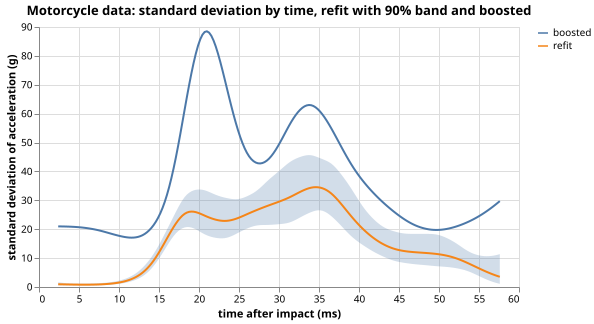

In [3]:
band = alt.Chart(curves).mark_area(opacity=0.25).encode(
    x=alt.X("times").title("time after impact (ms)"),
    y=alt.Y("lower").title("standard deviation of acceleration (g)"), y2="upper")
lines = alt.Chart(curves.unpivot(index="times", on=["refit", "boosted"],
                                 variable_name="fit", value_name="sd")).mark_line().encode(
    x="times", y="sd", color=alt.Color("fit").title(None))
(band + lines).properties(
    title="Motorcycle data: standard deviation by time, refit with 90% band and boosted",
    width=480, height=260)

The standard deviation is about
{eval}`round(float(curves["refit"][0]), 1)` g before the impact, peaks at about
{eval}`round(float(curves["refit"].max()), 0)` g around
{eval}`round(float(curves["times"][int(np.argmax(curves["refit"].to_numpy()))]), 0)` ms,
and falls afterwards. The band is pointwise and conditional on the terms and
on the smoothing parameters; `effects(..., corrected=True)` adds the
first-order uncertainty of the smoothing parameters.

## 6 Intervals

The Bayesian covariance of the joint coefficients is $A^{-1}$, with blocks
between parameters. A term's interval uses its own block, as in the
single-predictor refit. The corrected covariance
$A^{-1} + J V_\rho J^\top$, $J_{\cdot j} = \partial \hat\theta/\partial
\rho_j$, $V_\rho = 2 H_V^{-1}$ with $H_V$ the Hessian of $V$ (by central
differences of its gradient), adds the first-order uncertainty of the
smoothing parameters. Intervals for quantities that combine several
parameters, such as the centile $\mu + z_\alpha \sigma$ (the α-quantile of the response when its distribution is normal with mean $\mu$ and standard deviation $\sigma$), need the cross blocks.
`draws(newdata, n_draws)` samples $\theta \sim N(\hat\theta, A^{-1})$ (or
the corrected covariance), evaluates every parameter at the new rows on its
natural scale, and returns the draws; a derived quantity is computed draw by
draw and its interval read from the quantiles over the draws, the usual
posterior-simulation approach for GAMs {cite}`wood2017generalized`.

## 7 Implementation

The refit is implemented in the Rust core and called from Python and R.
